# YOLOv10-S baseline on UA-DETRAC

Compares the pretrained YOLOv10-S model (zero-shot) with a version fine-tuned on our data.

Set SMOKE_TEST as True to run as a test, put False if you want a real run.

## 1. CONFIG

In [ ]:
import sys, io, json, time, random, shutil, contextlib, subprocess
from pathlib import Path

import numpy as np
import pandas as pd
import yaml
import torch
from PIL import Image
import matplotlib.pyplot as plt

IN_COLAB = 'google.colab' in sys.modules

# set root directory to the parent of notebooks/ if we are in notebooks/, otherwise cwd
ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()

SMOKE_TEST = False   # True = quick test, False = real run

if IN_COLAB:
    COLAB_ZIP = Path('/content/drive/MyDrive/DATA255/processed.zip')     # zip of traffic-monitoring/data/processed
    DATA_DIR = Path('/content/processed')                               # where the zip is extracted
    OUTPUT_DIR = Path('/content/drive/MyDrive/DATA255/outputs/yolov10_baseline') 
else:
    DATA_DIR = ROOT / 'traffic-monitoring' / 'data' / 'processed'
    OUTPUT_DIR = ROOT / 'outputs' / 'yolov10_baseline'

MODEL = 'yolov10s.pt'
EPOCHS = 50
PATIENCE = 10       
IMGSZ = 640
BATCH = 16
SEED = 0
FRACTION = 1.0         

EVAL_CONF = 0.001       
COUNT_CONF = 0.25    
IOU_MATCH = 0.5         
SMOKE_TEST_IMAGES_PER_WEATHER = 10

if SMOKE_TEST:
    EPOCHS = 2
    FRACTION = 0.1
    OUTPUT_DIR = OUTPUT_DIR / 'smoke_test'

if torch.cuda.is_available():
    DEVICE = 0
elif torch.backends.mps.is_available():
    DEVICE = 'mps'
else:
    DEVICE = 'cpu'

# mapped COCO class IDs to our class IDs (0=car, 1=bus, 2=others)
COCO_TO_OURS = {2: 0,   # car   -> car
                5: 1,   # bus   -> bus
                7: 3}   # truck -> others

random.seed(SEED)
np.random.seed(SEED)
if not IN_COLAB:   # on Colab the folder is on Drive, so it is created after Drive is mounted (SETUP)
    OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

print(f'SMOKE_TEST={SMOKE_TEST}  DEVICE={DEVICE}  EPOCHS={EPOCHS}  FRACTION={FRACTION}')
print('DATA_DIR  :', DATA_DIR)
print('OUTPUT_DIR:', OUTPUT_DIR)

SMOKE_TEST=False  DEVICE=0  EPOCHS=50  FRACTION=1.0
DATA_DIR  : /content/processed
OUTPUT_DIR: /content/drive/MyDrive/DATA255/outputs/yolov10_baseline


## 2. SETUP

Colab only: connect Google Drive and unzip the dataset. Skipped on the Mac.

In [2]:
if IN_COLAB:
    from google.colab import drive
    drive.mount('/content/drive')
    subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', 'ultralytics', 'pycocotools'], check=True)
    if not DATA_DIR.exists():
        shutil.unpack_archive(COLAB_ZIP, DATA_DIR.parent)
    OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
else:
    print('Not on Colab: skipping')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


Load the dataset info and make the image lists and `data.yaml` copies used below. The original dataset is never changed.

In [ ]:
from ultralytics import YOLO
from pycocotools.coco import COCO
from pycocotools.cocoeval import COCOeval

# Read the original data.yaml (class names + split folders)
with open(DATA_DIR / 'data.yaml') as f:
    original_yaml = yaml.safe_load(f)
names = original_yaml['names']
CLASS_NAMES = list(names) if isinstance(names, list) else [names[i] for i in sorted(names)]
NUM_CLASSES = len(CLASS_NAMES)
SPLITS = ['train', 'val', 'test']

# Dataset view: OUTPUT_DIR/dataset_view/{images,labels}/{split} are symlinks to the real folders
VIEW_DIR = OUTPUT_DIR / 'dataset_view'
for split in SPLITS:
    image_dir = DATA_DIR / original_yaml[split]                       
    label_dir = DATA_DIR / original_yaml[split].replace('images', 'labels', 1)
    for kind, target in [('images', image_dir), ('labels', label_dir)]:
        link = VIEW_DIR / kind / split
        link.parent.mkdir(parents=True, exist_ok=True)
        if link.is_symlink() or link.exists():
            link.unlink()                  
        link.symlink_to(target.resolve(), target_is_directory=True)

manifest = pd.read_csv(DATA_DIR / 'frame_manifest.csv')
manifest['image'] = manifest['image_path'].map(lambda p: Path(p).stem)
manifest['image_file'] = [str(VIEW_DIR / 'images' / s / Path(p).name) for s, p in zip(manifest['split'], manifest['image_path'])]
manifest['label_file'] = [str(VIEW_DIR / 'labels' / s / f'{i}.txt') for s, i in zip(manifest['split'], manifest['image'])]
missing = [p for p in manifest['image_file'] if not Path(p).exists()]
assert not missing, f'{len(missing)} manifest images not found, e.g. {missing[:3]}'


test_df = manifest[manifest['split'] == 'test']
if SMOKE_TEST:
    n = min(SMOKE_TEST_IMAGES_PER_WEATHER, test_df['weather'].value_counts().min())
    test_df = test_df.groupby('weather').sample(n=n, random_state=SEED)
test_df = test_df.reset_index(drop=True)
WEATHERS = sorted(test_df['weather'].unique())

LIST_DIR = OUTPUT_DIR / 'image_lists'
LIST_DIR.mkdir(exist_ok=True)

def write_list(images, name):
    list_file = LIST_DIR / f'{name}.txt'
    list_file.write_text('\n'.join(images) + '\n')
    return str(list_file)

TRAIN_LIST = write_list(manifest.loc[manifest['split'] == 'train', 'image_file'], 'train')
VAL_LIST = write_list(manifest.loc[manifest['split'] == 'val', 'image_file'], 'val')

def make_yaml(test_images, name):
    yaml_file = OUTPUT_DIR / f'{name}.yaml'
    with open(yaml_file, 'w') as f:
        yaml.safe_dump({'path': str(VIEW_DIR), 'train': TRAIN_LIST, 'val': VAL_LIST,
                        'test': write_list(test_images, name), 'names': CLASS_NAMES}, f, sort_keys=False)
    return str(yaml_file)

RUNTIME_YAML = make_yaml(test_df['image_file'].tolist(), 'data_runtime')
WEATHER_YAMLS = {w: make_yaml(g['image_file'].tolist(), f'data_test_{w}') for w, g in test_df.groupby('weather')}

print('Classes:', CLASS_NAMES)
print('Runtime yaml:', RUNTIME_YAML)
display(pd.crosstab(manifest['weather'], manifest['split'], margins=True))
print(f'Evaluating on {len(test_df)} test images:', test_df['weather'].value_counts().to_dict())

Classes: ['car', 'bus', 'van', 'others']
Runtime yaml: /content/drive/MyDrive/DATA255/outputs/yolov10_baseline/data_runtime.yaml


split,test,train,val,All
weather,,,,
cloudy,402,3468,649,4519
night,521,3407,657,4585
rainy,800,2583,637,4020
sunny,766,2342,595,3703
All,2489,11800,2538,16827


Evaluating on 2489 test images: {'rainy': 800, 'sunny': 766, 'night': 521, 'cloudy': 402}


Helper functions for scoring. Both models are scored with the same code.

In [ ]:
BOX_COLS = ['x1', 'y1', 'x2', 'y2']


def load_ground_truth(images_df):
    # Reads the YOLO label files and return one row per box in pixel coordinates.
    rows = []
    for r in images_df.itertuples():
        width, height = Image.open(r.image_file).size   
        for line in Path(r.label_file).read_text().splitlines():
            if not line.strip():
                continue
            class_id, xc, yc, w, h = line.split()
            xc, w = float(xc) * width, float(w) * width
            yc, h = float(yc) * height, float(h) * height
            rows.append({'image': r.image, 'class_id': int(class_id),
                         'x1': xc - w / 2, 'y1': yc - h / 2, 'x2': xc + w / 2, 'y2': yc + h / 2})
    return pd.DataFrame(rows, columns=['image', 'class_id'] + BOX_COLS)


def predict_detections(model, images_df, conf, class_map=None):
    # Predicts boxes for the given images and returns one row per box in pixel coordinates.
    rows = []
    paths = images_df['image_file'].tolist()
    for start in range(0, len(paths), BATCH):
        results = model.predict(paths[start:start + BATCH], conf=conf, imgsz=IMGSZ, device=DEVICE, verbose=False)
        for result in results:
            image = Path(result.path).stem
            boxes = result.boxes
            for box, cls, score in zip(boxes.xyxy.tolist(), boxes.cls.int().tolist(), boxes.conf.tolist()):
                if class_map is not None:
                    if cls not in class_map:
                        continue                   
                    cls = class_map[cls]
                rows.append({'image': image, 'class_id': cls, 'confidence': score,
                             'x1': box[0], 'y1': box[1], 'x2': box[2], 'y2': box[3]})
        del results                                 
        if torch.cuda.is_available():
            torch.cuda.empty_cache()
    return pd.DataFrame(rows, columns=['image', 'class_id', 'confidence'] + BOX_COLS)


def coco_ap(gt, det, image_names, agnostic=False):
    # AP with pycocotools. Returns {name: (AP50, AP50_95)} per class plus 'all' (mean over classes).
    # Classes with no ground truth in these images get NaN. agnostic=True -> one 'vehicle' class.
    image_ids = {name: i + 1 for i, name in enumerate(image_names)}
    gt = gt[gt['image'].isin(image_ids)]
    det = det[det['image'].isin(image_ids)]
    cat_names = ['vehicle'] if agnostic else CLASS_NAMES
    to_cat = (lambda c: 1) if agnostic else (lambda c: int(c) + 1)   # COCO category IDs start at 1

    coco_gt = COCO()
    coco_gt.dataset = {
        'images': [{'id': i} for i in image_ids.values()],
        'categories': [{'id': k + 1, 'name': n} for k, n in enumerate(cat_names)],
        'annotations': [{'id': k + 1, 'image_id': image_ids[r.image], 'category_id': to_cat(r.class_id),
                         'bbox': [r.x1, r.y1, r.x2 - r.x1, r.y2 - r.y1],
                         'area': (r.x2 - r.x1) * (r.y2 - r.y1), 'iscrowd': 0}
                        for k, r in enumerate(gt.itertuples())],
    }
    has_gt = {n: (gt['class_id'] == k).any() if not agnostic else len(gt) > 0 for k, n in enumerate(cat_names)}

    if len(det) == 0:   # no detections at all: AP is 0 wherever there is ground truth
        out = {n: (0.0, 0.0) if has_gt[n] else (np.nan, np.nan) for n in cat_names}
    else:
        with contextlib.redirect_stdout(io.StringIO()):   # hide pycocotools' printouts
            coco_gt.createIndex()
            coco_det = coco_gt.loadRes([{'image_id': image_ids[r.image], 'category_id': to_cat(r.class_id),
                                         'bbox': [r.x1, r.y1, r.x2 - r.x1, r.y2 - r.y1], 'score': r.confidence}
                                        for r in det.itertuples()])
            ev = COCOeval(coco_gt, coco_det, 'bbox')
            ev.params.maxDets = [1, 10, 300]   # allow up to 300 boxes per image (busy traffic scenes)
            ev.evaluate()
            ev.accumulate()
        # precision has shape [IoU thresholds (0.5..0.95), recall points, class, area range, maxDets]
        precision = ev.eval['precision'][:, :, :, 0, -1]
        out = {}
        for k, n in enumerate(cat_names):
            p = precision[:, :, k]
            out[n] = (p[0][p[0] > -1].mean(), p[p > -1].mean()) if has_gt[n] else (np.nan, np.nan)

    out['all'] = tuple(np.nanmean([out[n][j] for n in cat_names]) for j in (0, 1))
    return out


def box_iou(a, b):
    # IoU between every box in a (N, 4) and every box in b (M, 4), both in x1, y1, x2, y2 format.
    x1 = np.maximum(a[:, None, 0], b[None, :, 0])
    y1 = np.maximum(a[:, None, 1], b[None, :, 1])
    x2 = np.minimum(a[:, None, 2], b[None, :, 2])
    y2 = np.minimum(a[:, None, 3], b[None, :, 3])
    inter = np.clip(x2 - x1, 0, None) * np.clip(y2 - y1, 0, None)
    area_a = (a[:, 2] - a[:, 0]) * (a[:, 3] - a[:, 1])
    area_b = (b[:, 2] - b[:, 0]) * (b[:, 3] - b[:, 1])
    return inter / (area_a[:, None] + area_b[None, :] - inter)


def precision_recall(gt, det, agnostic=False):
    # Precision and recall at confidence >= COUNT_CONF and IoU >= IOU_MATCH.
    # Detections are matched greedily (highest confidence first) to unmatched GT boxes.
    # Returns {name: (precision, recall)}; precision is NaN for a class with no detections.
    det = det[det['confidence'] >= COUNT_CONF].sort_values('confidence', ascending=False).copy()
    det['tp'] = False
    key = ['image'] if agnostic else ['image', 'class_id']
    gt_by_key = dict(list(gt.groupby(key)))
    for k, d in det.groupby(key):
        g = gt_by_key.get(k)
        if g is None:
            continue
        ious = box_iou(d[BOX_COLS].to_numpy(), g[BOX_COLS].to_numpy())
        used = np.zeros(len(g), dtype=bool)
        for i, idx in enumerate(d.index):         # d keeps the confidence order
            candidates = np.where(~used & (ious[i] >= IOU_MATCH))[0]
            if len(candidates):
                used[candidates[np.argmax(ious[i, candidates])]] = True
                det.at[idx, 'tp'] = True

    def pr(d, n_gt):
        return (d['tp'].mean() if len(d) else np.nan, d['tp'].sum() / n_gt if n_gt else np.nan)

    if agnostic:
        return {'vehicle': pr(det, len(gt))}
    out = {n: pr(det[det['class_id'] == c], (gt['class_id'] == c).sum()) for c, n in enumerate(CLASS_NAMES)}
    out['all'] = pr(det, len(gt))
    return out


def evaluate(gt, det, images_df):
    # evaltuate all detection metrics for one model, as a long table: group, metric, value.
    image_names = images_df['image'].tolist()
    gt = gt[gt['image'].isin(image_names)]
    rows = []
    ap, pr = coco_ap(gt, det, image_names), precision_recall(gt, det)
    for group in ['all'] + CLASS_NAMES:
        rows += [(group, 'mAP50', ap[group][0]), (group, 'mAP50_95', ap[group][1]),
                 (group, 'precision', pr[group][0]), (group, 'recall', pr[group][1])]
    # mAP over only the classes that have a COCO equivalent (a fairer zero-shot comparison)
    mapped = [CLASS_NAMES[c] for c in sorted(set(COCO_TO_OURS.values()))]
    rows += [('coco_mapped_classes', m, np.nanmean([ap[n][j] for n in mapped])) for j, m in enumerate(['mAP50', 'mAP50_95'])]
    ap_v, pr_v = coco_ap(gt, det, image_names, agnostic=True)['vehicle'], precision_recall(gt, det, agnostic=True)['vehicle']
    rows += [('vehicle', 'mAP50', ap_v[0]), ('vehicle', 'mAP50_95', ap_v[1]),
             ('vehicle', 'precision', pr_v[0]), ('vehicle', 'recall', pr_v[1])]
    for weather, g in images_df.groupby('weather'):
        ap_w = coco_ap(gt, det, g['image'].tolist())['all']
        rows += [(f'weather:{weather}', 'mAP50', ap_w[0]), (f'weather:{weather}', 'mAP50_95', ap_w[1])]
    return pd.DataFrame(rows, columns=['group', 'metric', 'value'])


def count_table(gt, det, images_df):
    # Count the number of boxes per image, per class, and overall, for both ground truth and predictions.
    det = det[det['confidence'] >= COUNT_CONF]
    counts = images_df[['image', 'sequence', 'frame', 'weather']].copy()
    for prefix, boxes in [('gt', gt), ('pred', det)]:
        per_class = (boxes.groupby(['image', 'class_id']).size().unstack(fill_value=0)
                     .reindex(index=counts['image'], columns=range(NUM_CLASSES), fill_value=0))
        for c, n in enumerate(CLASS_NAMES):
            counts[f'{prefix}_{n}'] = per_class[c].to_numpy()
        counts[f'{prefix}_total'] = per_class.sum(axis=1).to_numpy()
    return counts


def count_mae(counts):
    # Mean absolute counting error per image: overall, per class and per weather.
    err = lambda d, n: (d[f'pred_{n}'] - d[f'gt_{n}']).abs().mean()
    rows = [('all', 'count_MAE', err(counts, 'total'))]
    rows += [(n, 'count_MAE', err(counts, n)) for n in CLASS_NAMES]
    rows += [(f'weather:{w}', 'count_MAE', err(g, 'total')) for w, g in counts.groupby('weather')]
    return pd.DataFrame(rows, columns=['group', 'metric', 'value'])


test_gt = load_ground_truth(test_df)
print(f'{len(test_gt)} ground-truth boxes in {len(test_df)} test images')

13221 ground-truth boxes in 2489 test images


## 3. ZERO-SHOT BASELINE (test set)

The pretrained model with no training on our data. Its classes are mapped: car → car, bus → bus, truck → others.
COCO has no "van" class, so van AP is always 0 here.

In [5]:
zero_shot_model = YOLO(MODEL)
start = time.time()
zs_det = predict_detections(zero_shot_model, test_df, conf=EVAL_CONF, class_map=COCO_TO_OURS)
print(f'Zero-shot prediction: {time.time() - start:.0f}s, {len(zs_det)} boxes kept after class mapping')

zs_metrics = evaluate(test_gt, zs_det, test_df)
display(zs_metrics.pivot(index='group', columns='metric', values='value').round(3))

Zero-shot prediction: 37s, 124098 boxes kept after class mapping


metric,mAP50,mAP50_95,precision,recall
group,,,,
all,0.544,0.418,0.825,0.826
bus,0.881,0.675,0.896,0.867
car,0.875,0.617,0.837,0.873
coco_mapped_classes,0.725,0.558,NaN,NaN
others,0.420,0.381,0.074,0.578
van,0.000,0.000,NaN,0.000
vehicle,0.906,0.642,0.877,0.878
weather:cloudy,0.541,0.331,NaN,NaN
weather:night,0.561,0.395,NaN,NaN


## 4. FINE-TUNE

Train on the train split and check on val after each epoch. If training is interrupted, re-run this cell to continue.

In [6]:
RUN_DIR = OUTPUT_DIR / 'finetune'
LAST_PT = RUN_DIR / 'weights' / 'last.pt'
BEST_PT = RUN_DIR / 'weights' / 'best.pt'
DONE_FILE = RUN_DIR / 'TRAINING_DONE'

start = time.time()
if DONE_FILE.exists():
    print('Training already finished:', DONE_FILE.read_text())
elif LAST_PT.exists():
    print('Resuming from', LAST_PT)
    # data/device are passed again so a run started on the Mac can resume on Colab (and vice versa)
    YOLO(LAST_PT).train(resume=True, data=RUNTIME_YAML, device=DEVICE)
else:
    YOLO(MODEL).train(data=RUNTIME_YAML, epochs=EPOCHS, patience=PATIENCE, imgsz=IMGSZ, batch=BATCH,
                      seed=SEED, deterministic=True, device=DEVICE, fraction=FRACTION,
                      project=str(OUTPUT_DIR), name='finetune', exist_ok=True, plots=True)

if not DONE_FILE.exists():
    history = pd.read_csv(RUN_DIR / 'results.csv')
    info = {'epochs_completed': len(history), 'session_seconds': round(time.time() - start),
            'total_train_seconds': round(history['time'].iloc[-1]) if 'time' in history else None}
    DONE_FILE.write_text(json.dumps(info))
    print('Training finished:', info)

Training already finished: {"epochs_completed": 18, "session_seconds": 4393, "total_train_seconds": 4253}


## 5. FINAL EVALUATION (test set, Ultralytics)

The best fine-tuned model on the test set, overall and per-class scores, plus the confusion matrix and PR curve.

Ultralytics 8.4.194 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLOv10s summary (fused): 103 layers, 7,219,548 parameters, 0 gradients, 21.5 GFLOPs
val: Fast image access ✅ (ping: 0.8±0.1 ms, read: 85.2±41.2 MB/s, size: 68.7 KB)
val: Scanning /content/drive/MyDrive/DATA255/outputs/yolov10_baseline/dataset_view/labels/test... 2489 images, 1 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 2489/2489 257.8it/s 9.7s
val: New cache created: /content/drive/MyDrive/DATA255/outputs/yolov10_baseline/dataset_view/labels/test.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 156/156 5.9it/s 26.3s
                   all       2489      13221      0.714      0.613      0.653      0.487
Speed: 0.6ms preprocess, 5.4ms inference, 0.0ms loss, 1.2ms postprocess per image
Results saved to /content/drive/MyDrive/DATA255/outputs/yolov10_baseline/test_eval


,class,precision,recall,mAP50,mAP50_95
0,all,0.714,0.613,0.653,0.487
1,car,0.953,0.785,0.870,0.655
2,bus,0.943,0.799,0.897,0.684
3,van,0.659,0.602,0.656,0.479
4,others,0.300,0.267,0.191,0.130


Saved /content/drive/MyDrive/DATA255/outputs/yolov10_baseline/test_eval/confusion_matrix.png


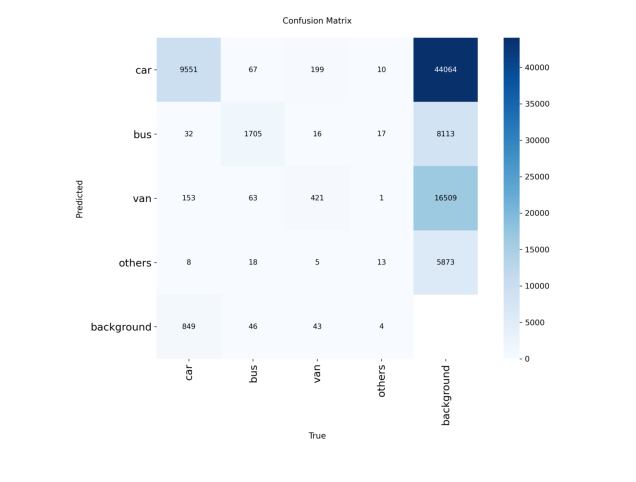

Saved /content/drive/MyDrive/DATA255/outputs/yolov10_baseline/test_eval/BoxPR_curve.png


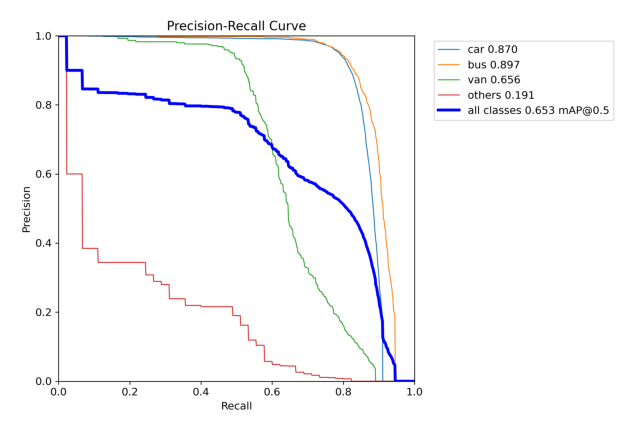

In [7]:
best_model = YOLO(BEST_PT)
test_results = best_model.val(data=RUNTIME_YAML, split='test', imgsz=IMGSZ, batch=BATCH, device=DEVICE,
                              project=str(OUTPUT_DIR), name='test_eval', exist_ok=True, plots=True, verbose=False)

box = test_results.box
rows = [{'class': 'all', 'precision': box.mp, 'recall': box.mr, 'mAP50': box.map50, 'mAP50_95': box.map}]
for i, c in enumerate(box.ap_class_index):
    p, r, ap50, ap = box.class_result(i)
    rows.append({'class': CLASS_NAMES[c], 'precision': p, 'recall': r, 'mAP50': ap50, 'mAP50_95': ap})
ultralytics_test = pd.DataFrame(rows)
ultralytics_test.to_csv(OUTPUT_DIR / 'test_metrics_ultralytics.csv', index=False)
display(ultralytics_test.round(3))

save_dir = Path(test_results.save_dir)
for name in ['confusion_matrix.png', 'BoxPR_curve.png']:
    if (save_dir / name).exists():
        print('Saved', save_dir / name)
        plt.figure(figsize=(8, 6))
        plt.imshow(Image.open(save_dir / name))
        plt.axis('off')
        plt.show()

## 6. PER-WEATHER EVALUATION (test set)

mAP for each weather on its own. No per-class numbers here, because some classes are missing in some weathers.

In [8]:
rows = []
for weather, yaml_file in WEATHER_YAMLS.items():
    r = best_model.val(data=yaml_file, split='test', imgsz=IMGSZ, batch=BATCH, device=DEVICE,
                       project=str(OUTPUT_DIR), name=f'test_eval_{weather}', exist_ok=True, plots=False, verbose=False)
    rows.append({'weather': weather, 'images': int((test_df['weather'] == weather).sum()),
                 'mAP50': r.box.map50, 'mAP50_95': r.box.map})
weather_results = pd.DataFrame(rows)
weather_results.to_csv(OUTPUT_DIR / 'test_metrics_by_weather_ultralytics.csv', index=False)
display(weather_results.round(3))

Ultralytics 8.4.194 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLOv10s summary (fused): 103 layers, 7,219,548 parameters, 0 gradients, 21.5 GFLOPs
val: Fast image access ✅ (ping: 0.8±0.1 ms, read: 75.8±2.2 MB/s, size: 60.0 KB)
val: Scanning /content/drive/MyDrive/DATA255/outputs/yolov10_baseline/dataset_view/labels/test... 402 images, 1 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 402/402 246.3it/s 1.6s
val: New cache created: /content/drive/MyDrive/DATA255/outputs/yolov10_baseline/dataset_view/labels/test.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 26/26 6.1it/s 4.2s
                   all        402       2258      0.856      0.593      0.765      0.505
Speed: 0.6ms preprocess, 5.8ms inference, 0.0ms loss, 1.4ms postprocess per image
Ultralytics 8.4.194 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLOv10s summary (fused): 103 layers, 7,219,548 parameters, 0 gradients, 21.5 GFL

,weather,images,mAP50,mAP50_95
0,cloudy,402,0.765,0.505
1,night,521,0.624,0.443
2,rainy,800,0.711,0.543
3,sunny,766,0.950,0.753


## 7. EXAMPLE PREDICTIONS

Two test images per weather with the predicted boxes drawn on.

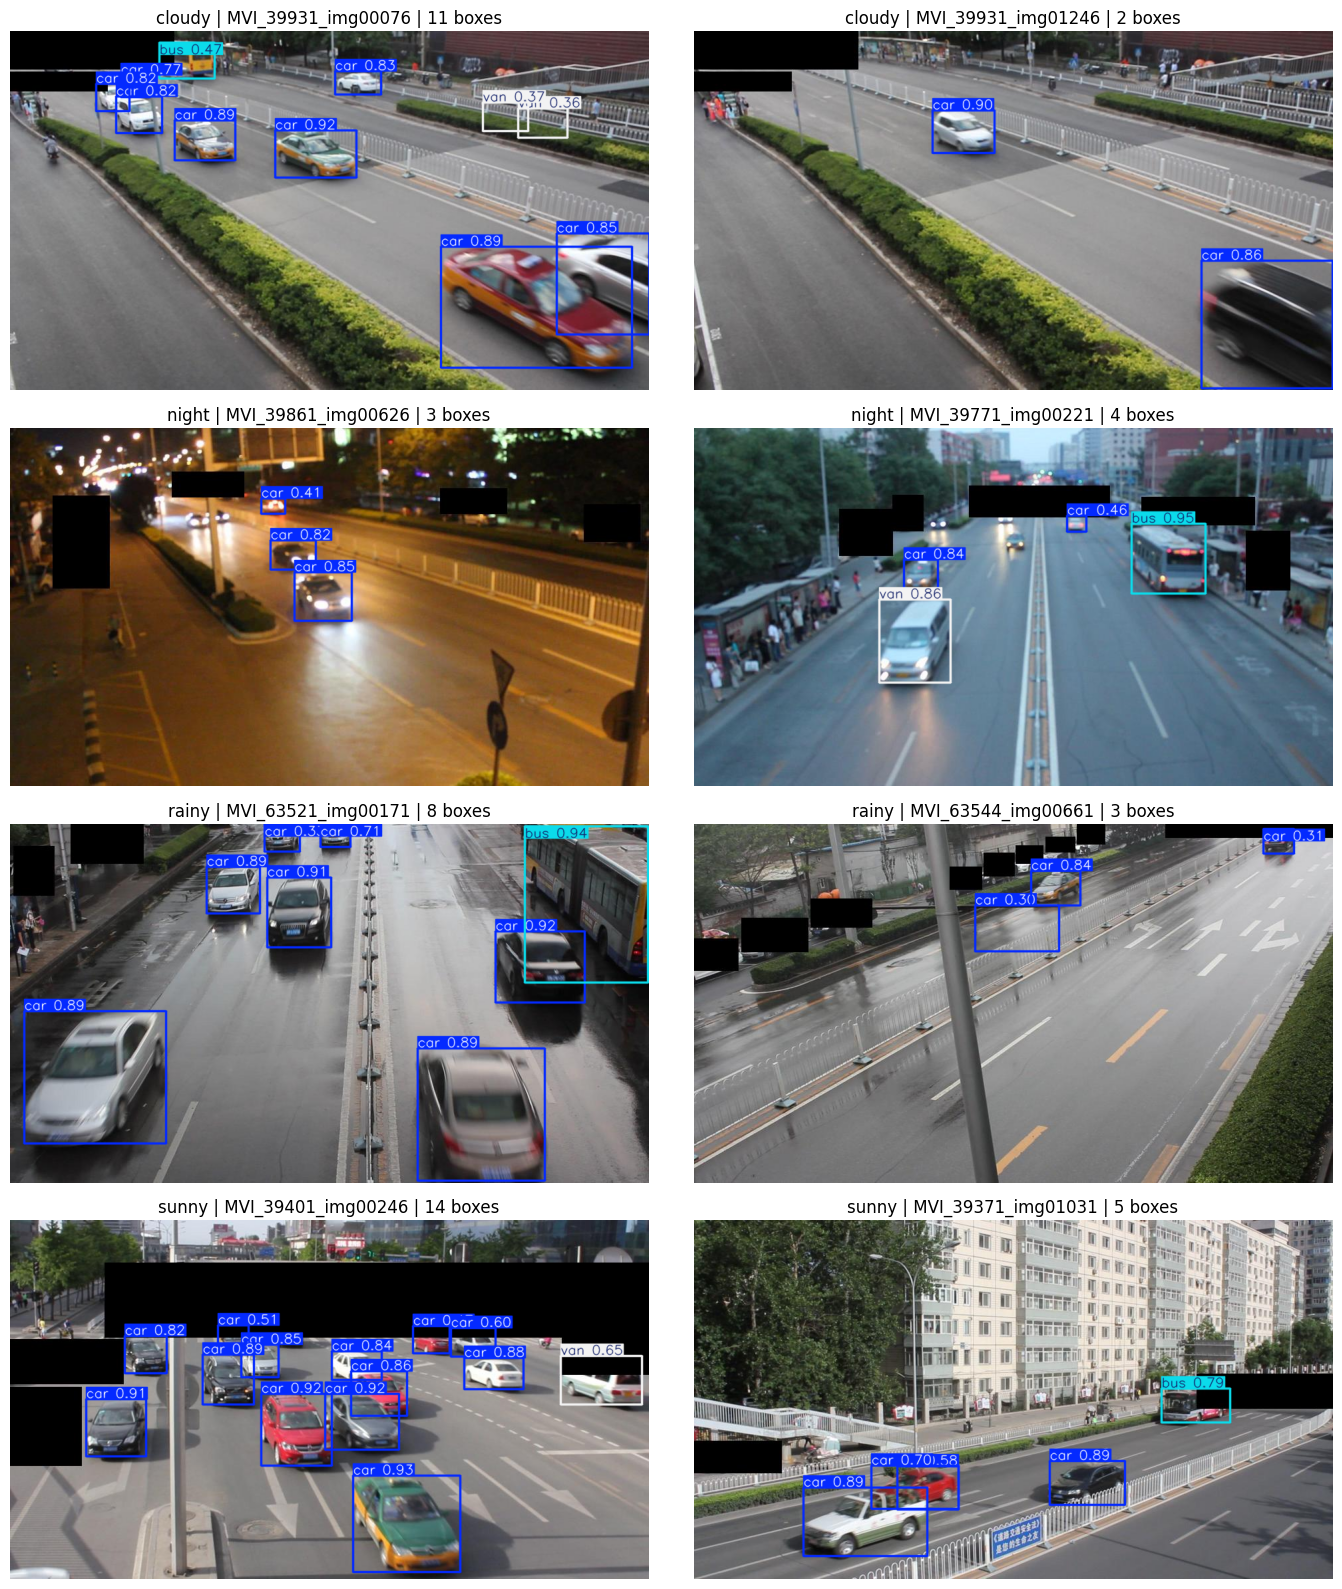

Saved examples to /content/drive/MyDrive/DATA255/outputs/yolov10_baseline/examples


In [ ]:
EXAMPLE_DIR = OUTPUT_DIR / 'examples'
EXAMPLE_DIR.mkdir(exist_ok=True)
examples = test_df.groupby('weather').sample(n=2, random_state=SEED)
fig, axes = plt.subplots(len(WEATHERS), 2, figsize=(14, 4 * len(WEATHERS)), squeeze=False)
for ax, row in zip(axes.flat, examples.itertuples()):
    result = best_model.predict(row.image_file, conf=COUNT_CONF, imgsz=IMGSZ, device=DEVICE, verbose=False)[0]
    result.save(filename=str(EXAMPLE_DIR / f'{row.weather}_{row.image}.jpg'))
    ax.imshow(result.plot()[:, :, ::-1])   
    ax.set_title(f'{row.weather} | {row.image} | {len(result.boxes)} boxes')
    ax.axis('off')
plt.tight_layout()
plt.show()
print('Saved examples to', EXAMPLE_DIR)

## 8. DETECTIONS EXPORT

Save every confident prediction on the test images to `detections.csv`.

In [ ]:
start = time.time()
ft_det = predict_detections(best_model, test_df, conf=EVAL_CONF)
print(f'Fine-tuned prediction: {time.time() - start:.0f}s')
ft_metrics = evaluate(test_gt, ft_det, test_df)
detections = (ft_det[ft_det['confidence'] >= COUNT_CONF]
              .merge(test_df[['image', 'sequence', 'frame', 'weather']], on='image', how='left'))
detections['class_name'] = detections['class_id'].map(dict(enumerate(CLASS_NAMES)))
detections = detections[['image', 'sequence', 'frame', 'weather', 'class_id', 'class_name', 'confidence'] + BOX_COLS]
detections.to_csv(OUTPUT_DIR / 'detections.csv', index=False)
print(f'{len(detections)} detections written to', OUTPUT_DIR / 'detections.csv')
display(detections.head())

Fine-tuned prediction: 32s
12250 detections written to /content/drive/MyDrive/DATA255/outputs/yolov10_baseline/detections.csv


,image,sequence,frame,weather,class_id,class_name,confidence,x1,y1,x2,y2
0,MVI_39051_img00001,MVI_39051,1,sunny,0,car,0.825748,242.253525,450.018127,442.883881,539.973450
1,MVI_39051_img00001,MVI_39051,1,sunny,0,car,0.789121,866.026978,314.300293,919.118408,348.889771
2,MVI_39051_img00006,MVI_39051,6,sunny,0,car,0.822869,848.955200,319.220306,904.798706,356.841736
3,MVI_39051_img00006,MVI_39051,6,sunny,0,car,0.767671,144.737213,476.055634,360.204651,540.000000
4,MVI_39051_img00011,MVI_39051,11,sunny,0,car,0.834052,831.274109,322.823181,892.055054,361.193054


## 9. COUNTING

How many vehicles each model counts per image vs. the true number. Count MAE = average miss per image (lower is better).

In [11]:
ft_counts = count_table(test_gt, ft_det, test_df)
zs_counts = count_table(test_gt, zs_det, test_df)
ft_counts.to_csv(OUTPUT_DIR / 'counts_per_image.csv', index=False)

ft_count_mae, zs_count_mae = count_mae(ft_counts), count_mae(zs_counts)
display(zs_count_mae.merge(ft_count_mae, on=['group', 'metric'], suffixes=('_zero_shot', '_fine_tuned')).round(3))

,group,metric,value_zero_shot,value_fine_tuned
0,all,count_MAE,0.822,0.956
1,car,count_MAE,0.791,0.834
2,bus,count_MAE,0.149,0.184
3,van,count_MAE,0.275,0.201
4,others,count_MAE,0.137,0.033
5,weather:cloudy,count_MAE,1.241,1.112
6,weather:night,count_MAE,0.814,1.451
7,weather:rainy,count_MAE,0.534,0.952
8,weather:sunny,count_MAE,0.909,0.540


## 10. RESULTS TABLE

Zero-shot vs. fine-tuned on every metric, saved as `yolov10_metrics.csv`.

In [ ]:
zs_all = pd.concat([zs_metrics, zs_count_mae])
ft_all = pd.concat([ft_metrics, ft_count_mae])
results = zs_all.merge(ft_all, on=['group', 'metric'], suffixes=('_zs', '_ft'))
results = results.rename(columns={'value_zs': 'zero_shot', 'value_ft': 'fine_tuned'})
results['change'] = results['fine_tuned'] - results['zero_shot']
results.to_csv(OUTPUT_DIR / 'yolov10_metrics.csv', index=False)
print('Saved', OUTPUT_DIR / 'yolov10_metrics.csv', '| SMOKE_TEST =', SMOKE_TEST)
with pd.option_context('display.max_rows', 200):
    display(results.round(3))

Saved /content/drive/MyDrive/DATA255/outputs/yolov10_baseline/yolov10_metrics.csv | SMOKE_TEST = False


,group,metric,zero_shot,fine_tuned,change
0,all,mAP50,0.544,0.629,0.086
1,all,mAP50_95,0.418,0.470,0.052
2,all,precision,0.825,0.872,0.047
3,all,recall,0.826,0.808,-0.018
4,car,mAP50,0.875,0.860,-0.014
5,car,mAP50_95,0.617,0.650,0.033
6,car,precision,0.837,0.901,0.065
7,car,recall,0.873,0.816,-0.057
8,bus,mAP50,0.881,0.887,0.006
9,bus,mAP50_95,0.675,0.676,0.000
